# N114: measured two-update fixed-context checks

Status: **complete**.

N114 changes the stalled-copy acceptance test from immediate J improvement to
measured H2 cumulative improvement. N113 is preserved; its currently running E
arm was stopped by user request. The new F controller starts from the ORIGINAL
image-model/optimizer/RNG parent, same ordered 91,968 reserved images, same
{0, 1/8, 1/4} original-nominal LR grid, four-head TRAIN-only fitted predictor,
88 rich inputs, action/sequence-dependent calibration and health-floor rules.
All 4,032 offline images remain excluded from online training. Calibration and
test diagnostics are inherited byte-for-byte; no fitting or tuning on TEST.

Normal H2 model rollouts, 5% feasible-action exploration, 384-arrival readouts,
512-consecutive-constraint-blocked audit trigger and 256-blocked-arrival repeat
cadence stay unchanged. Objective-selected skips do not trigger audits.

At each audit, restore independent temporary complete learner states and measure
the six positive-first plans (a,b), a in {1/8,1/4}, b in {0,1/8,1/4}. This includes
four plans with TWO actual copied updates plus two train/skip comparators. Reuse
first-step states: a complete audit requires six actual copied updates, not ten.
The skip/skip reference has exact cost 2*J_before. Both copied steps use the
CURRENT arriving image. Step two has its own deterministic augmentation seed,
paired across candidate plans. This is the declared fixed-context experiment;
no future real image or task label is accessed. Actual model and optimizer states
evolve within each copied plan, including Adam momentum.

A sequence qualifies only when both measured states retain both pre-decision
frozen RankMe/variance floors and J_first+J_second < 2*J_before - 1e-6. A temporary
first-step J increase is permitted; an intermediate health breach is not. Choose
the lowest cumulative-cost qualifying plan. Commit ONLY its exact FIRST model,
optimizer, modes and RNG state. Discard the second-step state. Replan on the next
real image; the copied second step is a fixed-context scenario, not a guarantee
for that future real image. If no sequence qualifies, leave the live plant intact.
Floors do not relax, and no additional update is applied when adopting a copy.

Predictor feedback remains identical to N113 E: valid measured FIRST-step trials
have total weight one per audit arrival and one forgetting tick, with one max
normalized calibration score per audit parent. A committed first state is not
learned twice. Second copied transitions are diagnostics only; they do not enter
the predictor or adaptive uncertainty buffers, since their repeated-image context
differs from the actual next-image calibration distribution. Anchors advance only
on committed plant updates. Numerical failures provide no labels or valid paths.

All trial states exist in memory only. Store metric/loss/validity/pass arrays for
the six paths, selected plan, actual trial count and elapsed audit time. The two
DEFLATE checkpoint generations store only the committed learner and full causal
predictor, bounds, starvation-clock and RNG state. Report copied-update budgets
separately from committed training, including first-step J increases accepted
because of lower measured cumulative cost.

Before the main run, a read-only diagnostic restores the stopped N113 E learner
and tests its last 16 already-arrived audited images. It never mutates that learner,
fits a predictor, accesses future real images or transfers any fitted state into
the new run. This diagnostic and earlier streams are development data already
inspected; results are not fresh confirmatory evidence or formal safety guarantees.

Preflight uses offline TRAIN images only. Checks cover exact full/resumed GPU
continuation, causal trace replay, exact committed-optimizer update accounting,
discarding rejected/second-step states, actual winner equality to a separately
reproduced first-step state, failed first/second trial exclusion and transient-J
acceptance logic.


| Arm | Saved images | Plant updates | Predictor feedback arrivals | Available late probe (%) | Recorded time (min) |
| --- | ---: | ---: | ---: | ---: | ---: |
| H2 · Measured two-step copy checks | 91,968 | 3,531 | 3,717 | 62.859 | 51.76 |

Current run coverage: **91,968**. Available table means use each arm's saved coverage; primary comparisons use common scheduled30k--91,968 checkpoints.

## Positive-update one-step forecast RMSE

| Arm | Output | Active model | Frozen shadow, same states/actions | Persistence | Positive updates |
| --- | --- | ---: | ---: | ---: | ---: |
| H2 · Measured two-step copy checks | RankMe | 0.0047411 | 0.00591774 | 0.00820173 | 3,531 |
| H2 · Measured two-step copy checks | Reconstruction loss | 0.000401917 | 0.000829227 | 0.00069085 | 3,531 |
| H2 · Measured two-step copy checks | Variance | 1.95267e-05 | 3.10643e-05 | 3.70869e-05 | 3,531 |

RMSE is in native metric units. Different policies visit different states; the frozen-shadow comparison is paired within each plant trajectory. Per-action and two-step numbers/counts are saved in comparison.json.

## Preserved stalled-state diagnostic

Tested 16 already-arrived images: 96 valid copied H2 sequences, 90 healthy at BOTH steps, 0 beating skip/skip on cumulative J. 0 images permit first-step re-entry. This read-only diagnostic never adapts or transfers the stalled learner.


## Balanced audit linear accuracy (%)

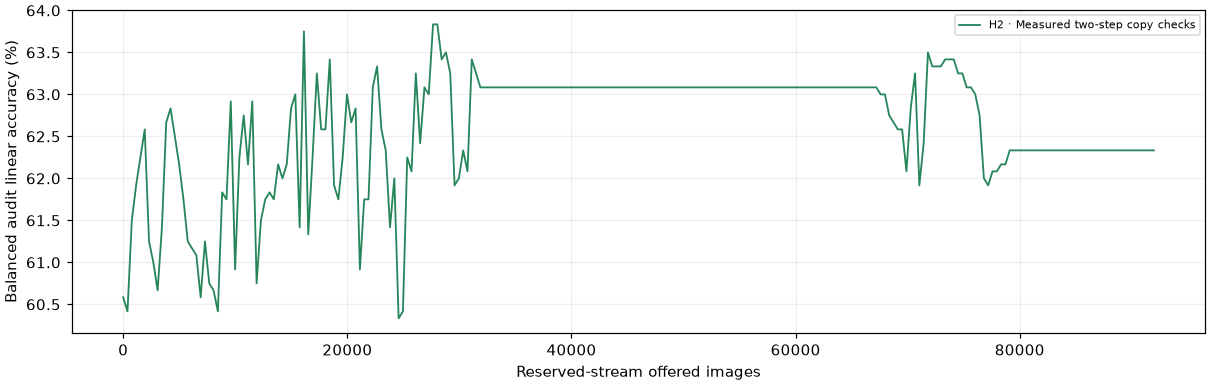



## RankMe

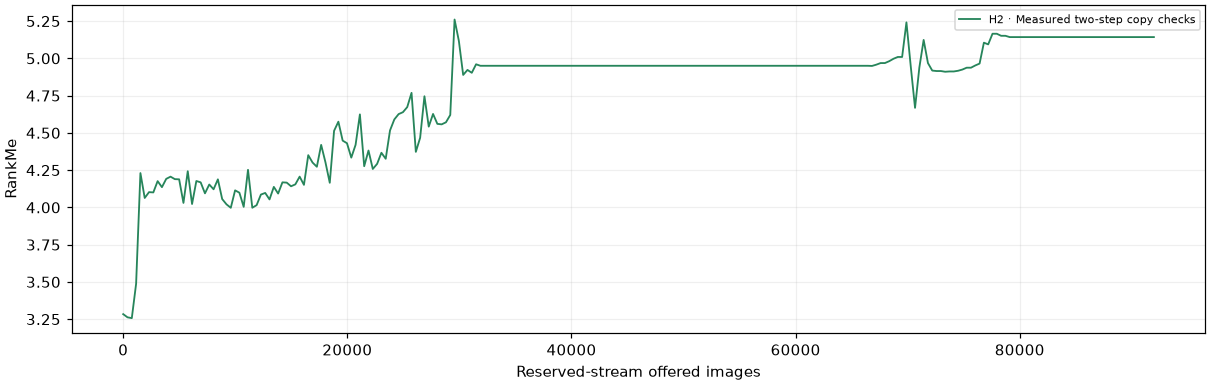



## Fixed-bank reconstruction loss

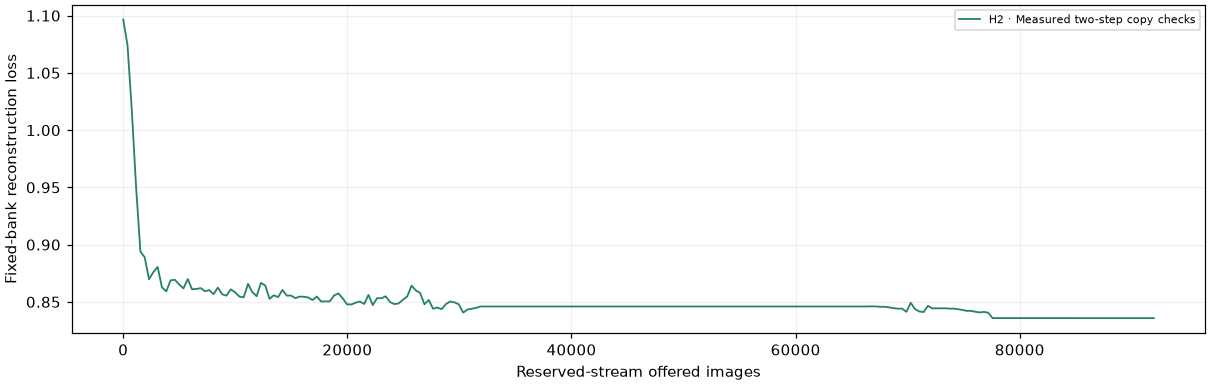



## Variance

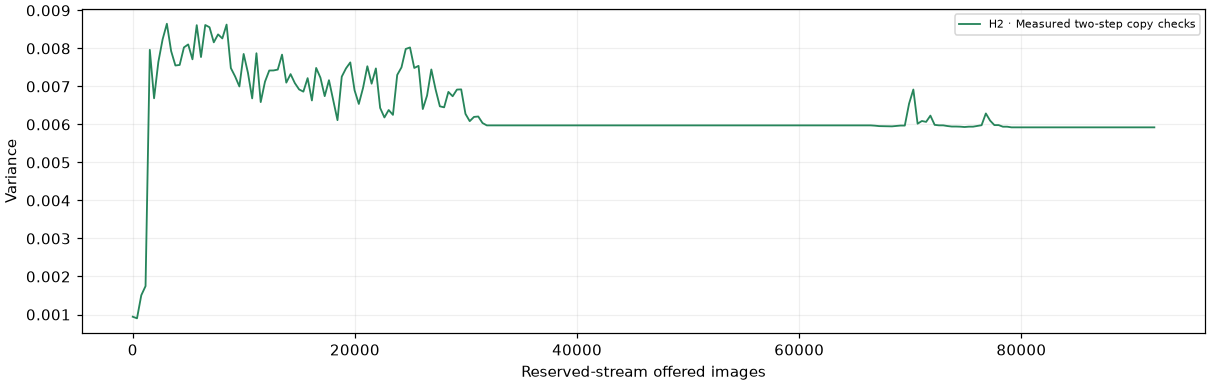



## Original fixed-bank J

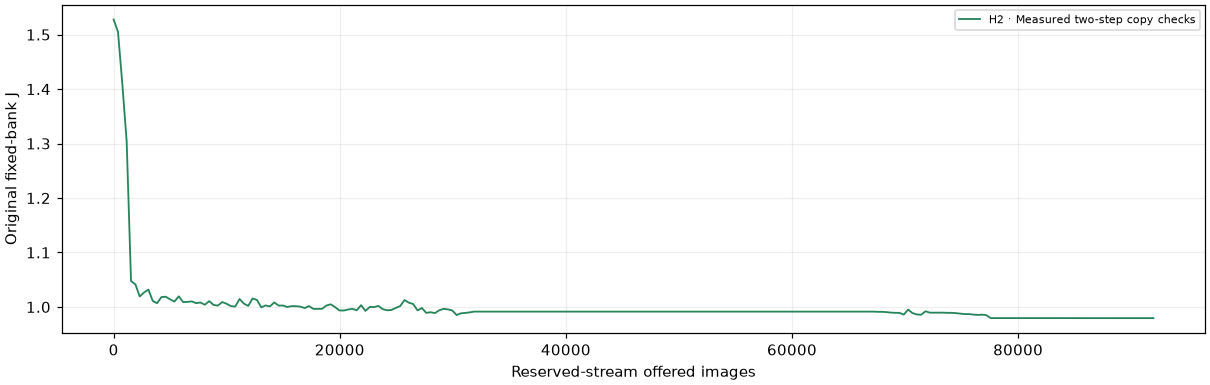



## Covariance

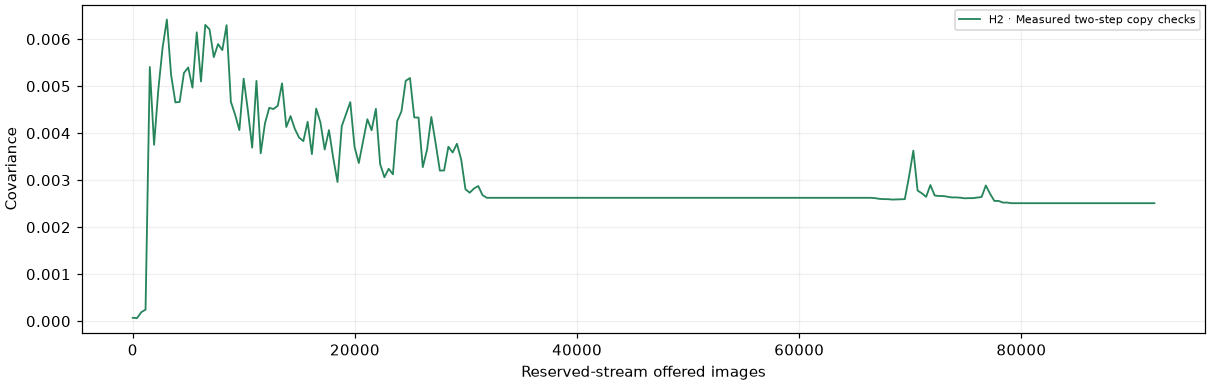



## Actual plant outputs and one-step forecasts

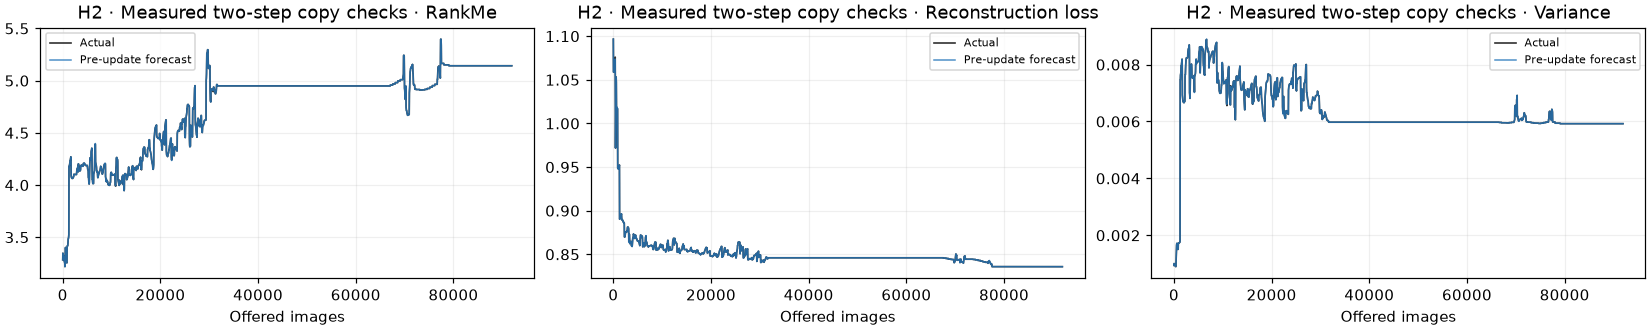

Display subsamples every32 arrivals; RMSE uses all successful positive updates and excludes identity skips.

## One-step positive-update RMSE

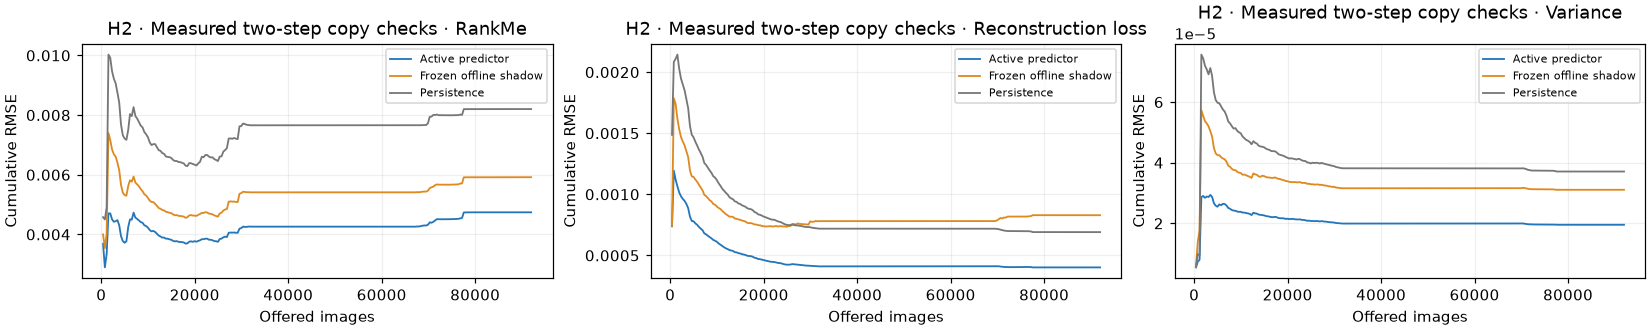



## Two-step nontrivial-window RMSE

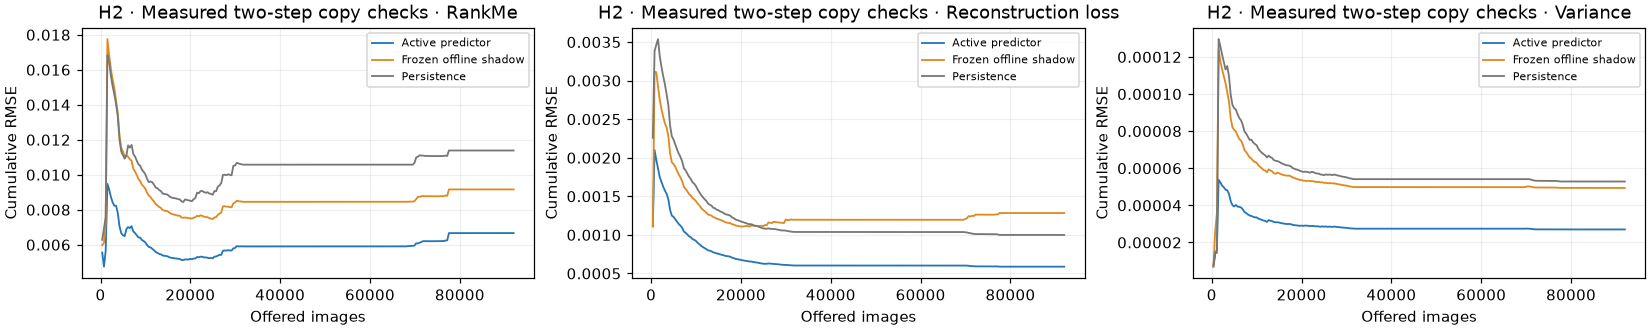



## Plant update and rate budgets

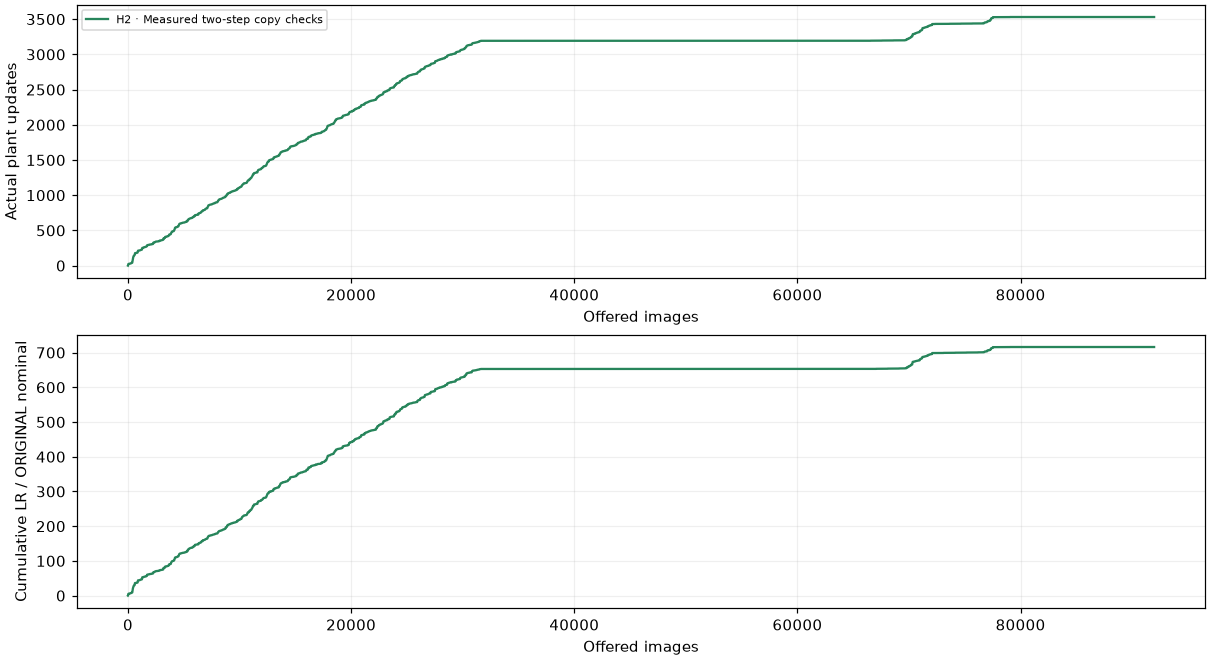



## Transition-model adaptation

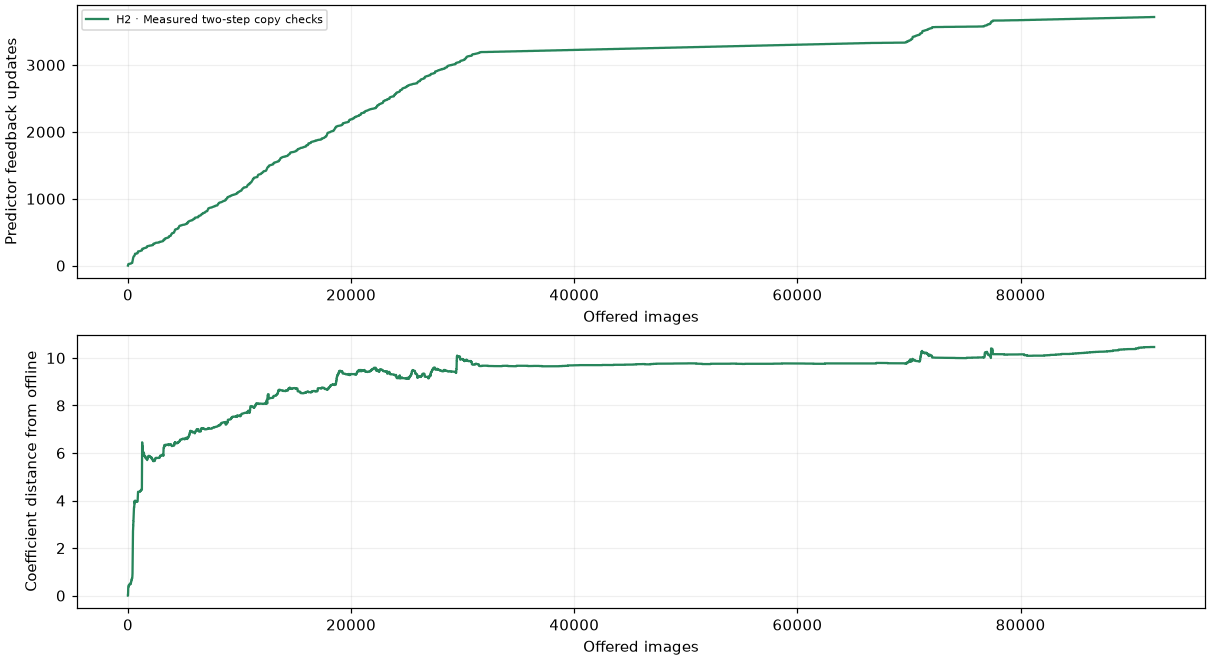



## Executed learning-rate actions

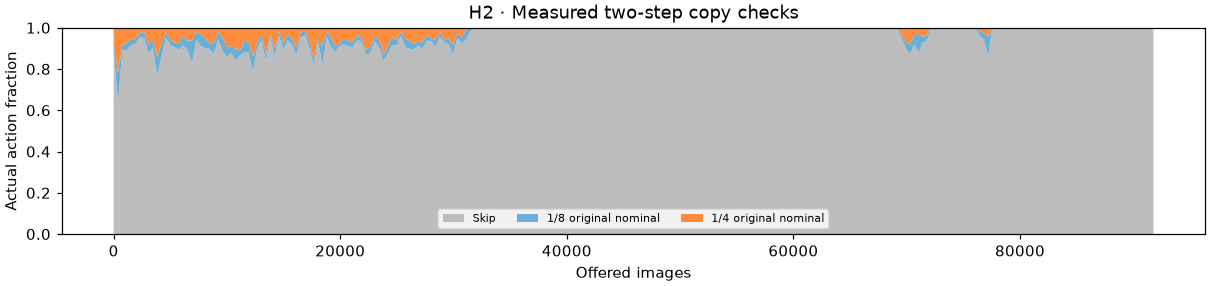



## Actual trained-image losses

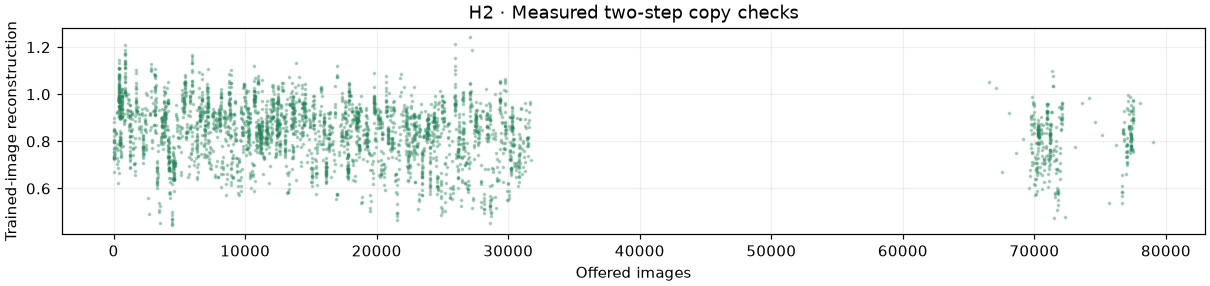



## Audit: linear task metrics

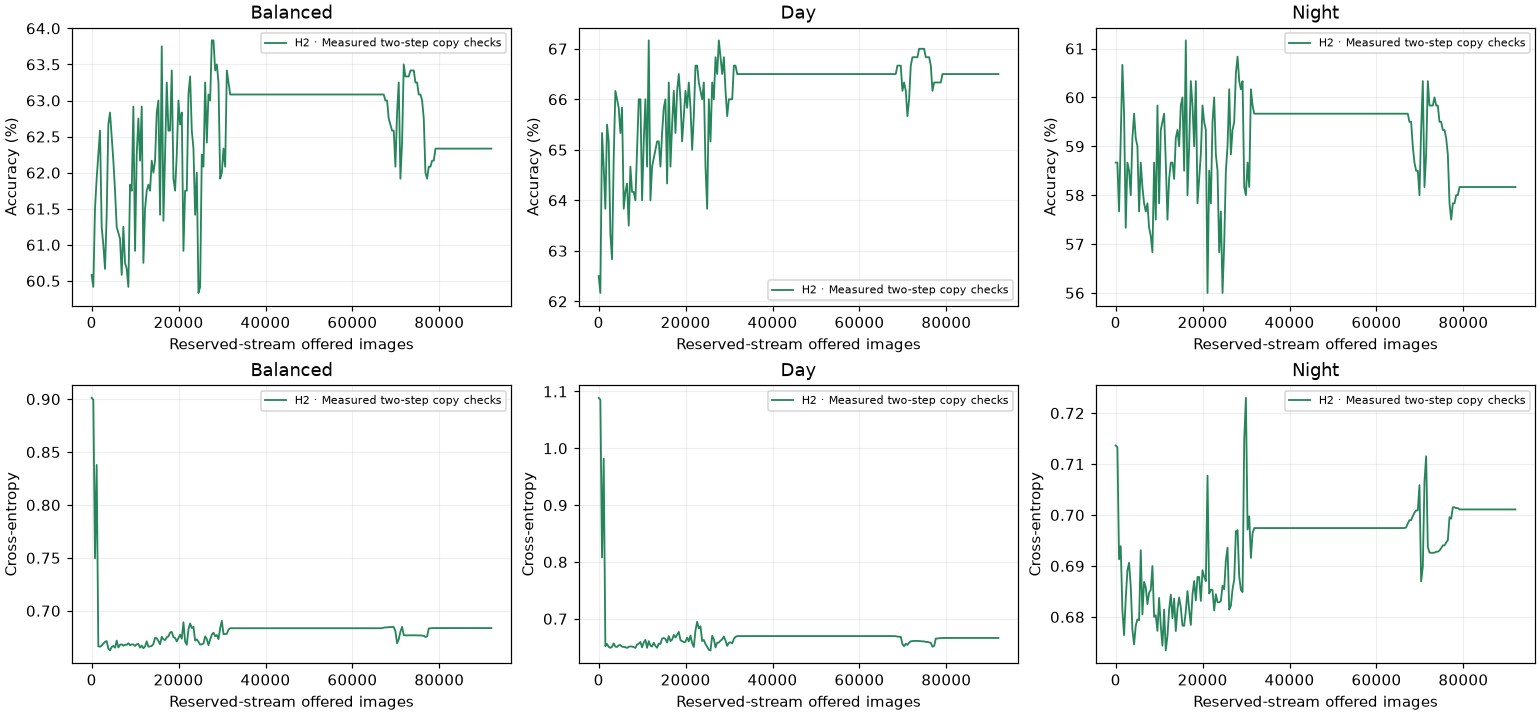



## Audit: knn task metrics

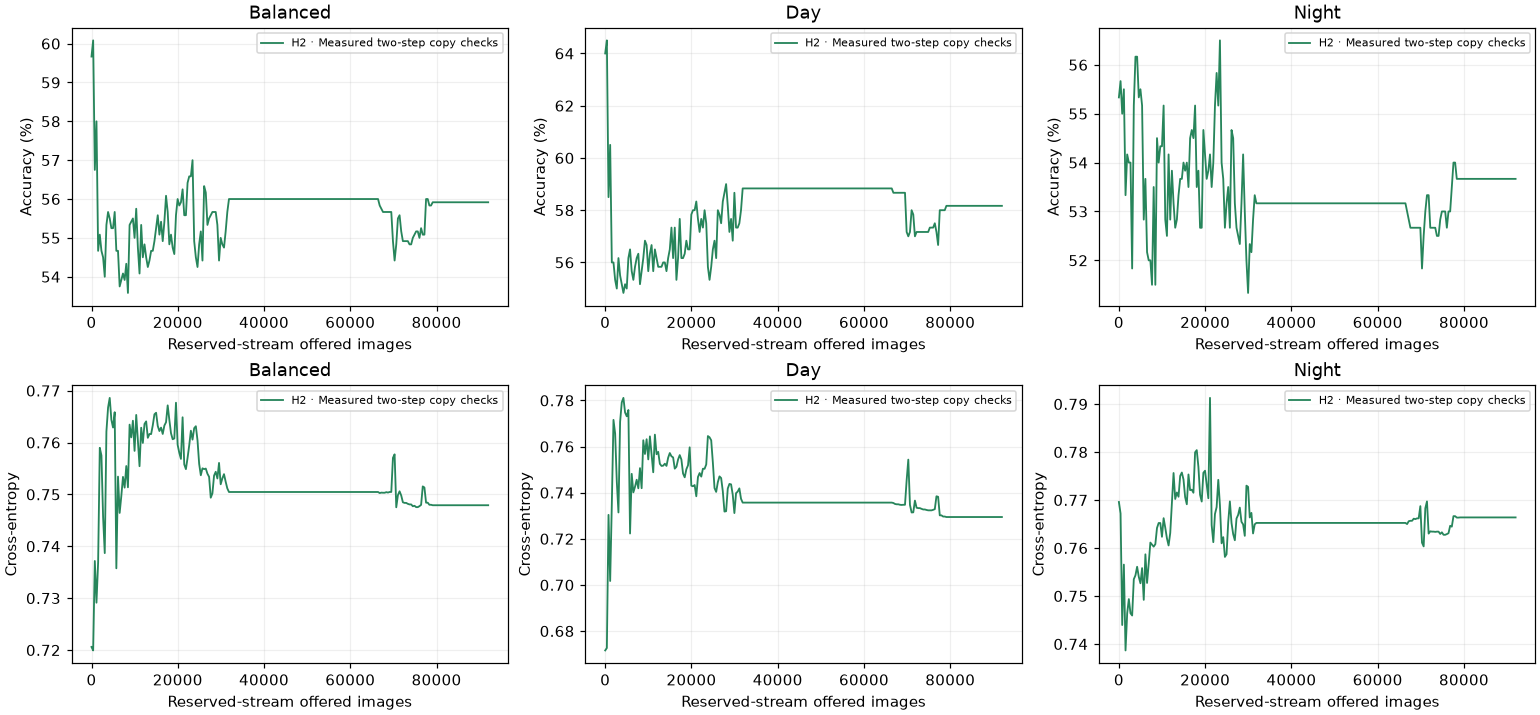



## Previous evaluation: linear task metrics

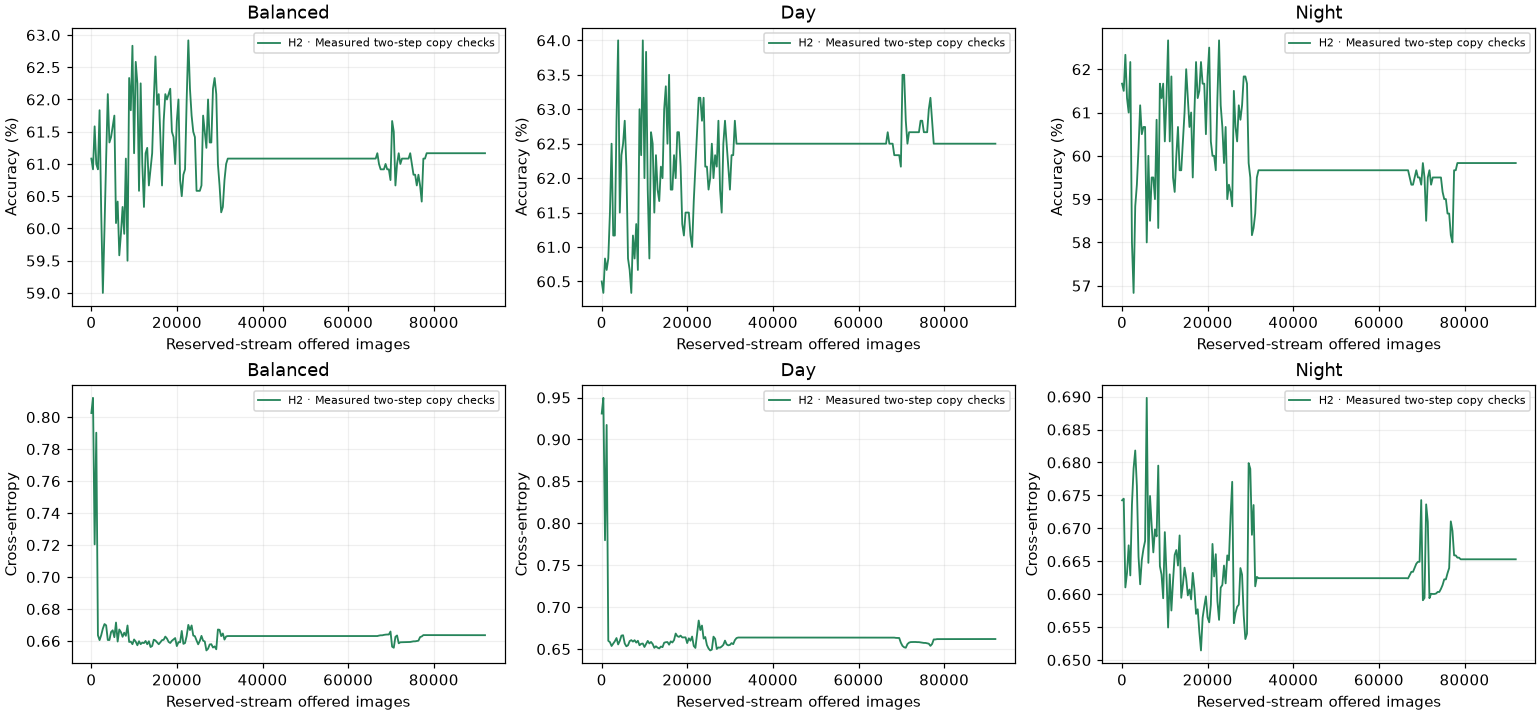



## Previous evaluation: knn task metrics

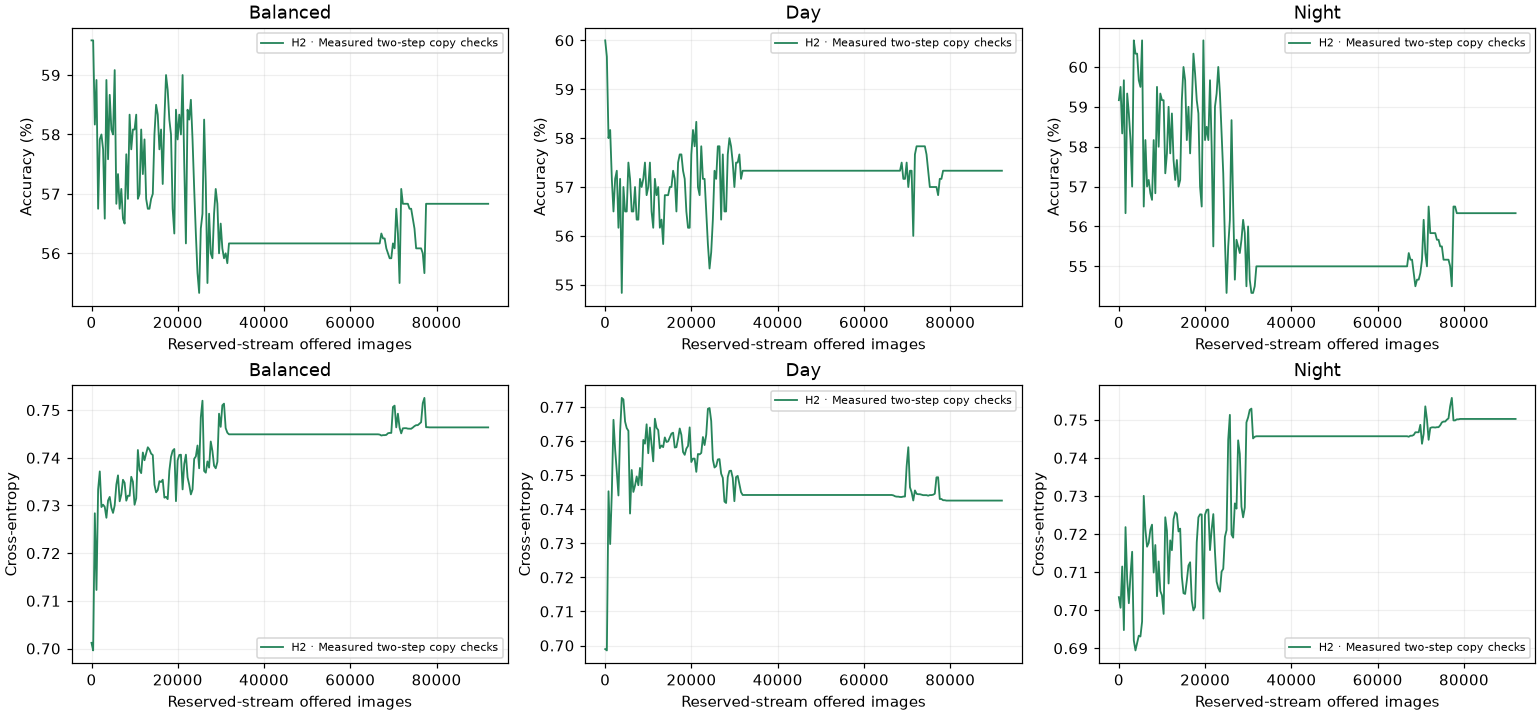



## Additional representation metrics

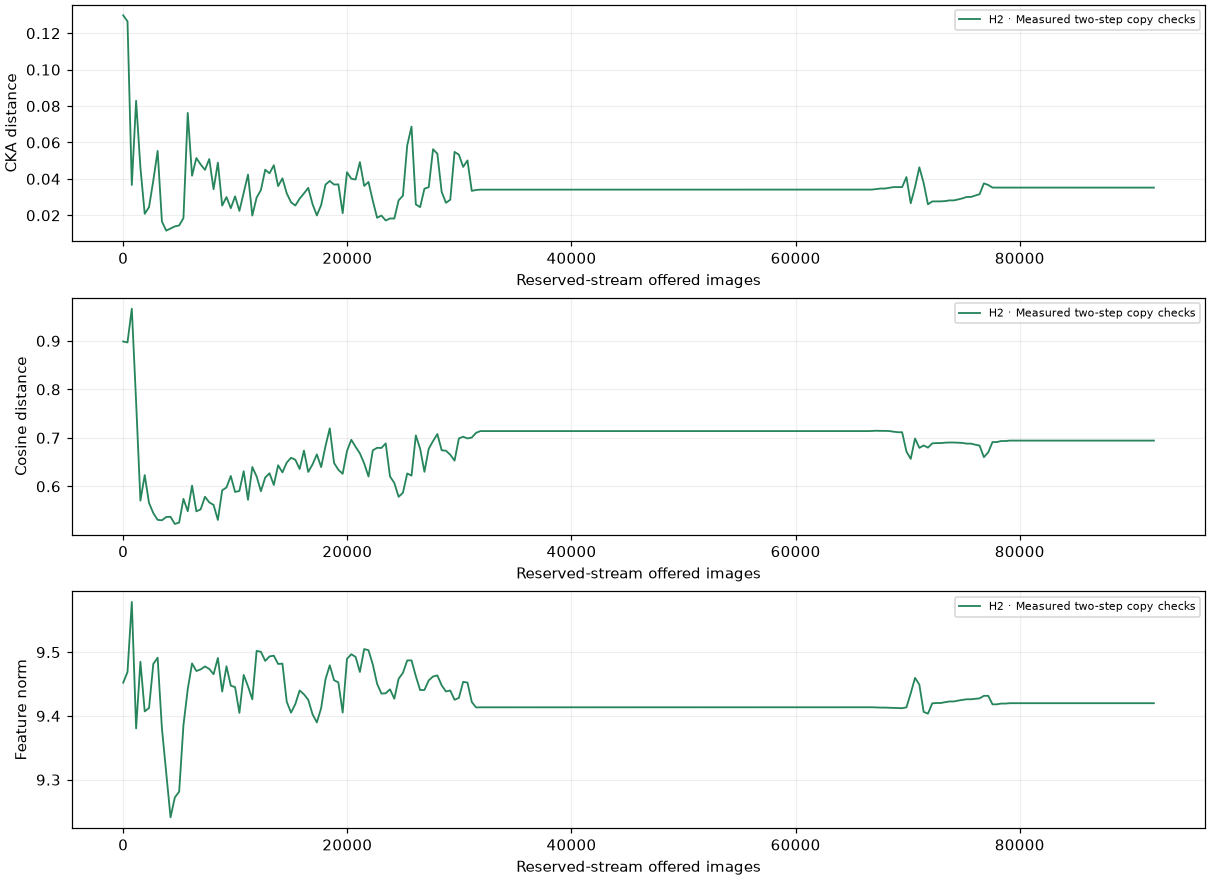



## Secondary evaluation health

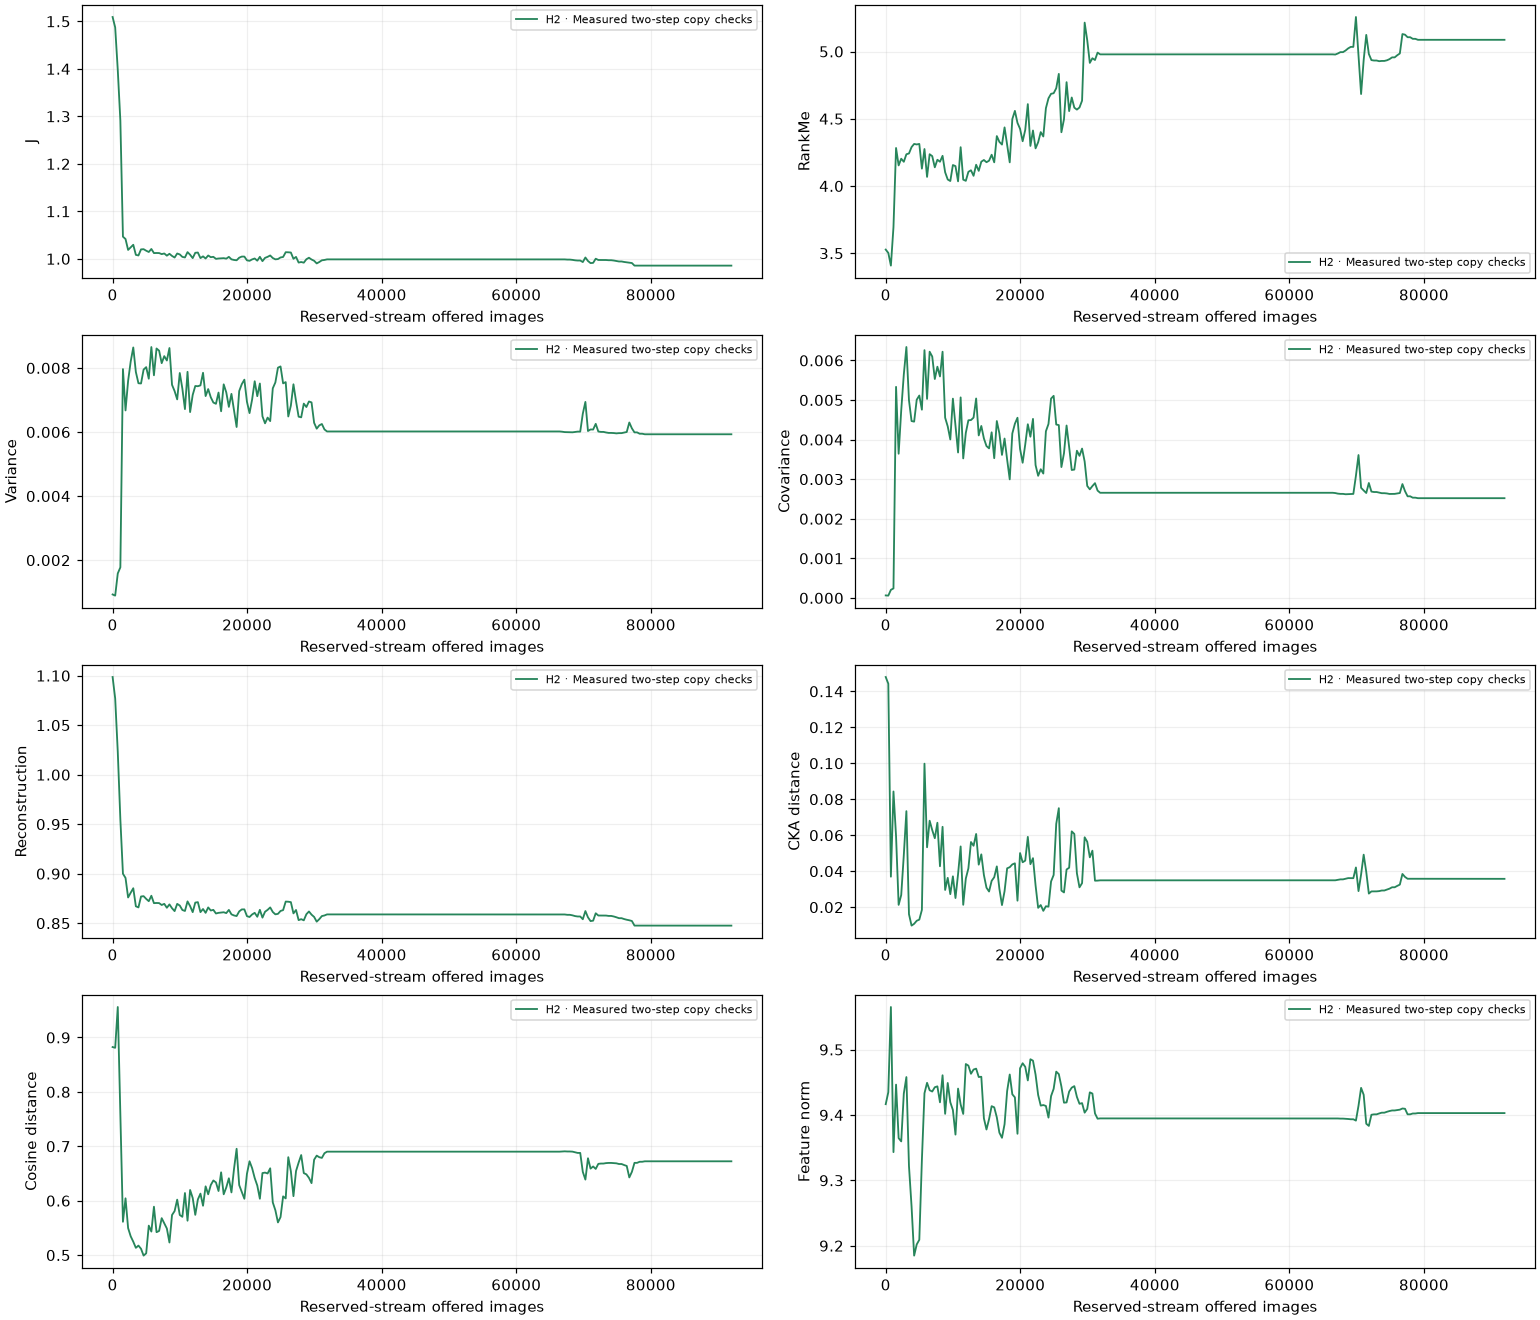



## Actual health versus pre-action causal floors

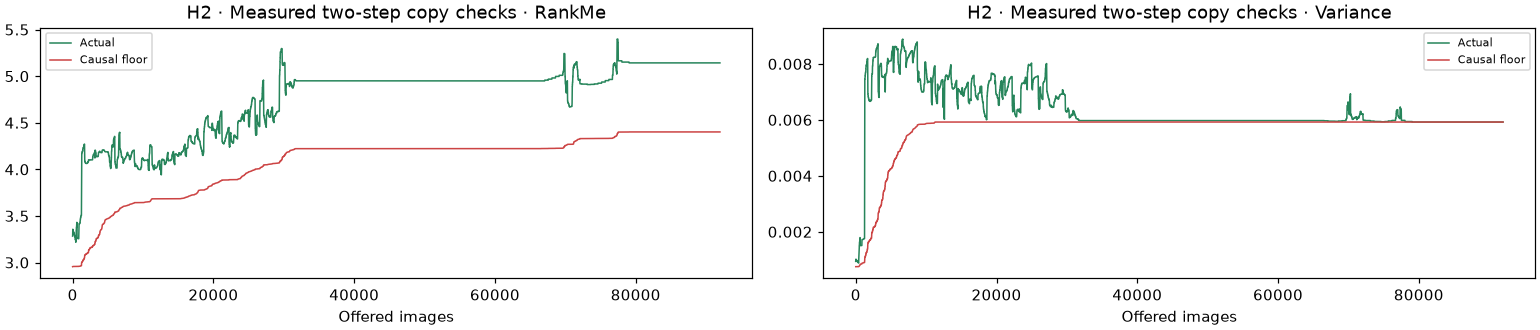



## Prequential chosen-action bound coverage

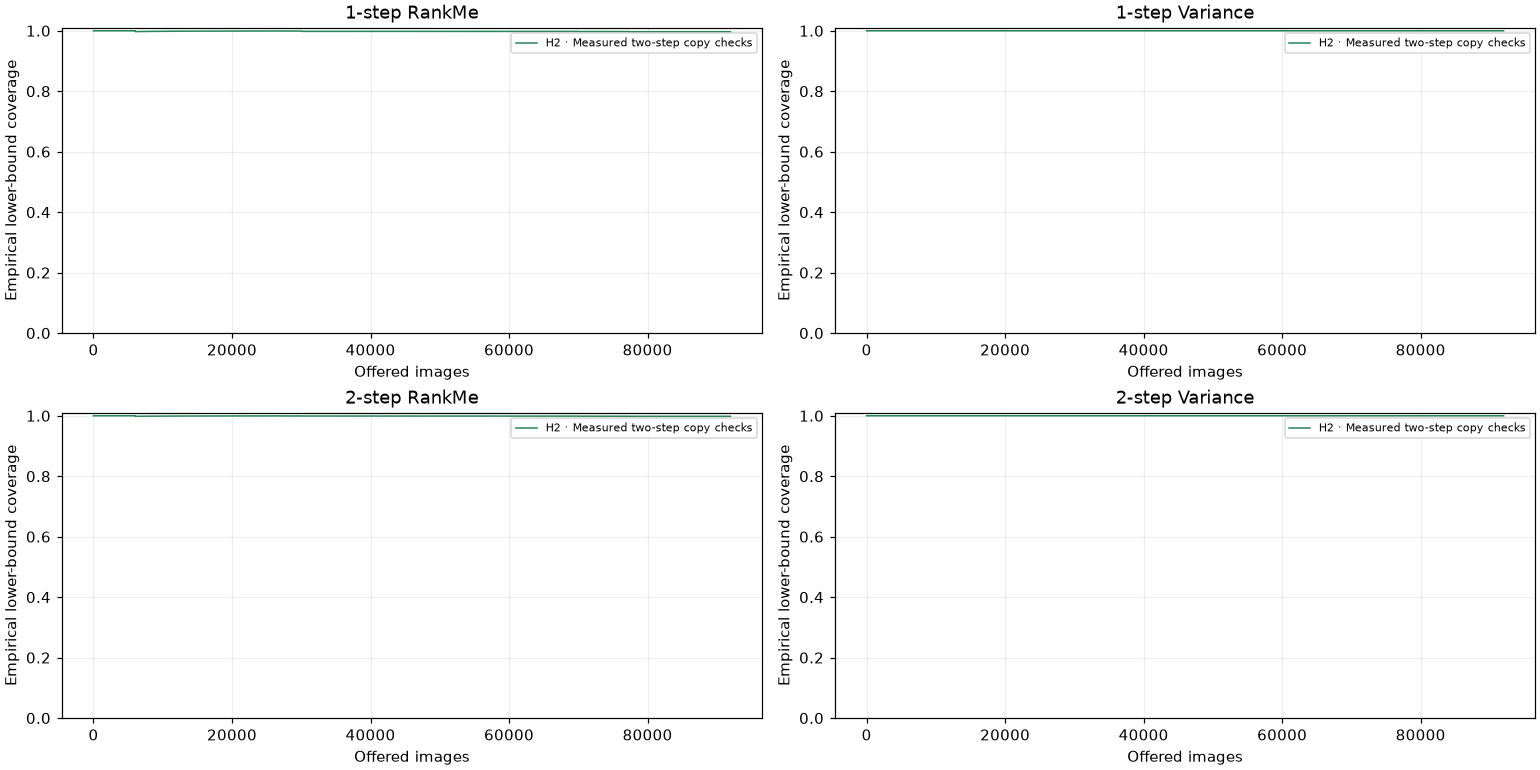

One-step positive updates; two-step nontrivial actual pairs. No claim of policy-independent joint online coverage.

## Filtering, recovery and actual violations

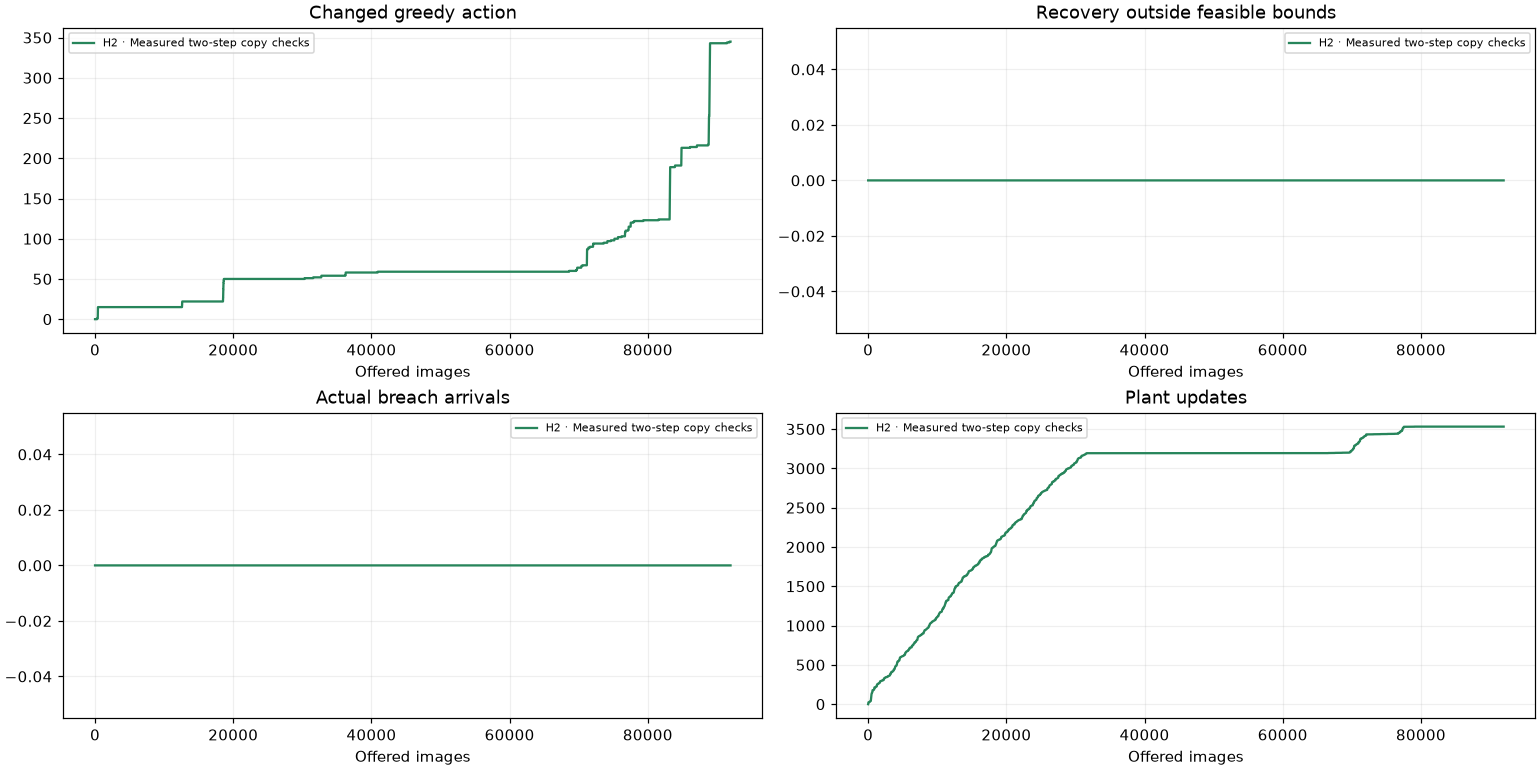



## Direct performance-head prediction error

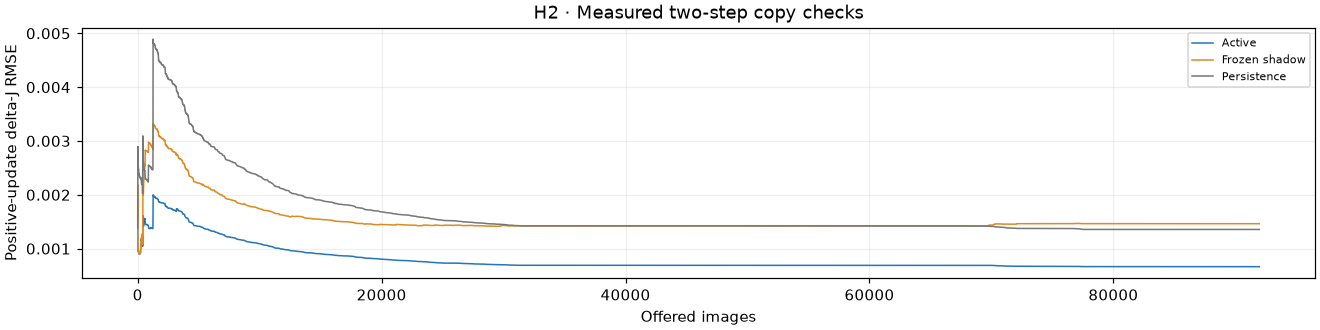



## Audit cost, measured feedback and verified re-entry

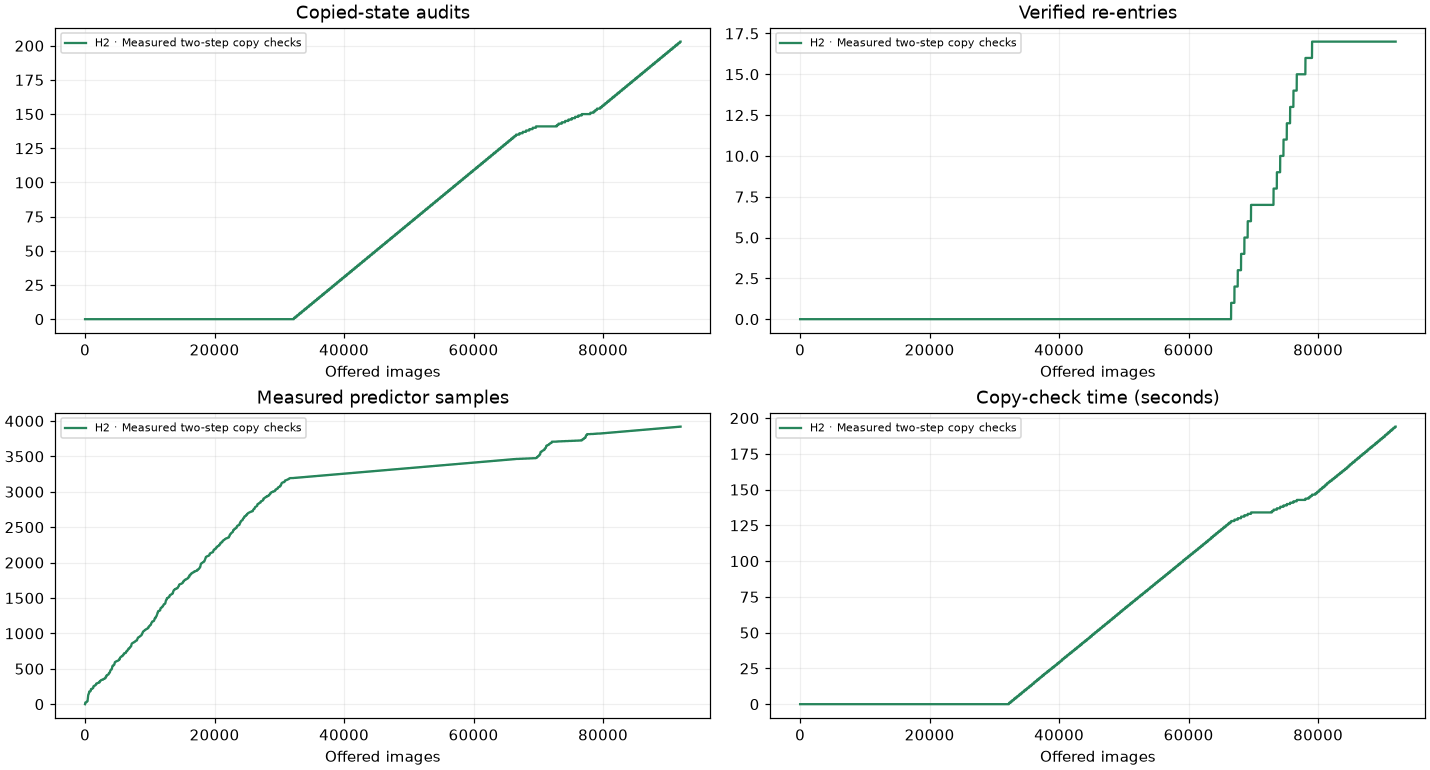

Trials use temporary memory only. Predictor samples include real measurements from uncommitted copies; plant budgets count only committed updates.

## Measured two-update costs and committed re-entry

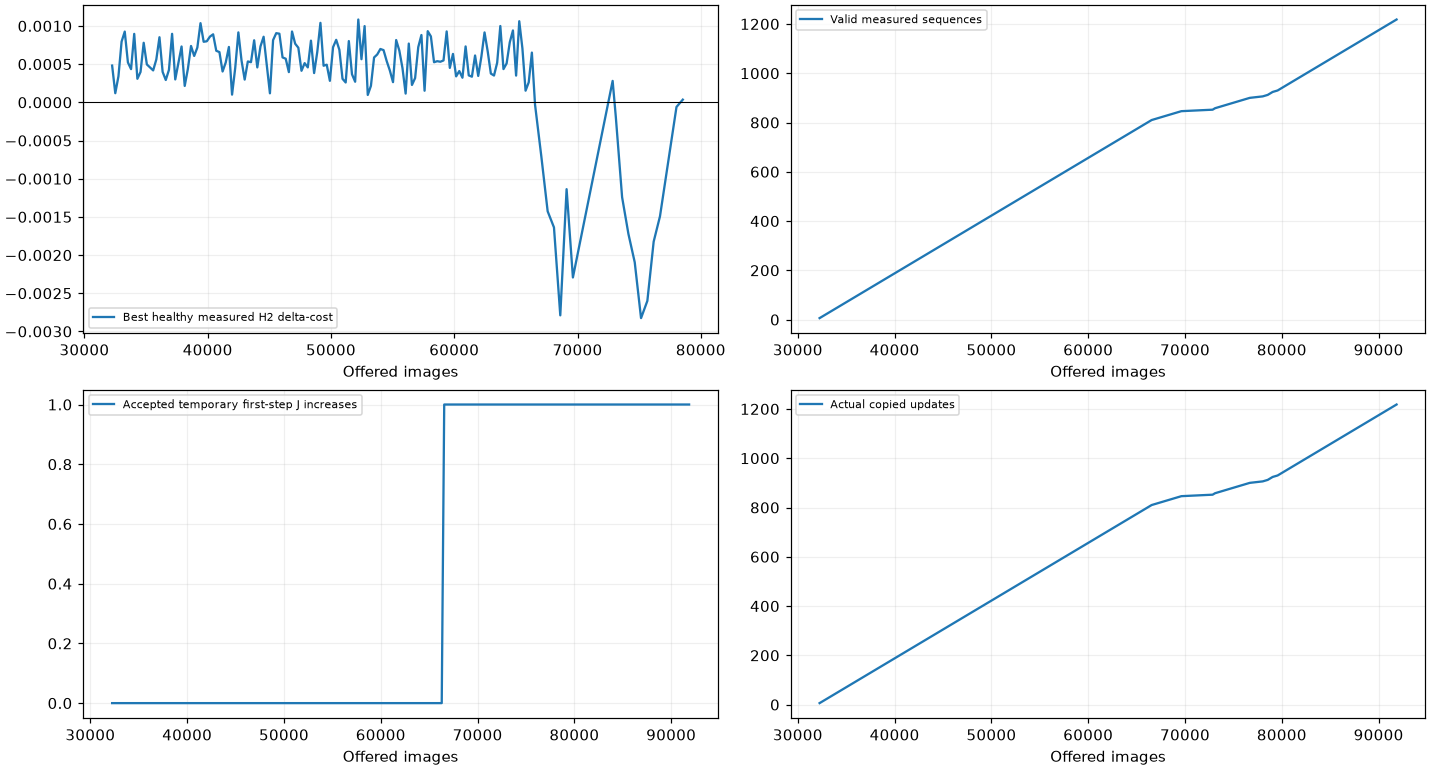

Both measured health states must pass. Only the selected FIRST state is committed; the repeated-image second state is discarded.